# **Dataset:** Netflix Movies and TV Shows

**Dataset Source:** https://www.kaggle.com/datasets/shivamb/netflix-shows?resource=download

**About Dataset:** This dataset contains information about Netflix shows, including their content type, title, director, country, date added, release year, rating, duration, genres, and description.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("netflix_titles.csv")
print("Dataset loaded successfully!!")

Dataset loaded successfully!!


In [ ]:
print("     ---------------- DATASET HEAD ---------------- ")
print(df.head()) # Displays the first 5 (by-default) rows of dataset

print("\n   ---------------- DATASET SHAPE ----------------")
print(df.shape) # Displays the number of rows and columns

print("\n    ---------------- COLUMN NAMES ----------------")
print(df.columns.tolist()) # Displays the name of all columns

print("\n    ---------------- DATASET INFORMATION ----------------")
df.info() # Displays the dataset information (data-types and non-null counts)

print("\n    ---------------- DATASET DESCRIPTION ----------------")
print(df.describe()) # Displays the descriptive statistics of numerical columns

     ---------------- DATASET HEAD ---------------- 
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          20

**Numerical Columns:**
- release_year

**Catagorical Columns:**

 - type
 - country
 - director
 - rating
 - duration
 - listed_in

**Identifiers / Descriptive Text:**
 - show_id
 - title
 - cast
 - description

# **Research Questions**

1. How has the balance between Movies and TV Shows changed across release years?
3. Which countries contribute the most Netflix titles, and how does the distribution differ between Movies and TV Shows?
4. How do content ratings differ between Movies and TV Shows, and how do missing or unusual ratings affect the comparison?


These questions will guide the cleaning, statistical analysis, group comparisons, and visualizations. The conclusions will be based on the results obtained from the dataset.

### **Handling Missing Values**

In [ ]:
print("   MISSING VALUES  ")
print()
print(df.isna().sum())
print("\nDataset Shape: ",df.shape)

   MISSING VALUES  

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Dataset Shape:  (8807, 12)


**Missing Value Analysis**

The dataset contains missing values in several columns. The largest number of missing values occurs in the `director` column, followed by `country` and `cast`. Only four records have a missing content rating, making `rating` relatively complete. Missing values will be handled according to the purpose of each column rather than removing entire rows unnecessarily.

In [ ]:
columns_to_fill = ["director", "cast", "country", "date_added", "duration"]
for column in columns_to_fill:
  df[column] = df[column].fillna("Unknown")

df["rating"] = df["rating"].fillna(df["rating"].mode()[0])

print("Missing values after cleaning: ")
print(df.isna().sum())

print("\nDataset shape: ", df.shape)

Missing values after cleaning: 
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Dataset shape:  (8807, 12)


### **Feature Engineering**

In [ ]:
df["date_added"] = pd.to_datetime(df["date_added"], errors = "coerce")
print(df["date_added"].head())

0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[ns]


In [ ]:
df['duration_value'] = df['duration'].str.extract(r'(\d+)').astype(float)

In [ ]:
# Extracting Movie Duration
def movie_duration(value):
    if isinstance(value, str) and "min" in value:
        return int(value.split()[0])
    else:
        return np.nan

df["Movie Duration (min)"] = df["duration"].apply(movie_duration)

print(df[["title", "type", "duration", "Movie Duration (min)"]].head(10))

                              title     type   duration  Movie Duration (min)
0              Dick Johnson Is Dead    Movie     90 min                  90.0
1                     Blood & Water  TV Show  2 Seasons                   NaN
2                         Ganglands  TV Show   1 Season                   NaN
3             Jailbirds New Orleans  TV Show   1 Season                   NaN
4                      Kota Factory  TV Show  2 Seasons                   NaN
5                     Midnight Mass  TV Show   1 Season                   NaN
6  My Little Pony: A New Generation    Movie     91 min                  91.0
7                           Sankofa    Movie    125 min                 125.0
8     The Great British Baking Show  TV Show  9 Seasons                   NaN
9                      The Starling    Movie    104 min                 104.0


In [ ]:
# Creating Release Period
df["Release Period"] = np.where(df['release_year'] < 2010, "Before 2010", "2010 or Later")
print(df[["title", "release_year", "Release Period"]].head(10))

                              title  release_year Release Period
0              Dick Johnson Is Dead          2020  2010 or Later
1                     Blood & Water          2021  2010 or Later
2                         Ganglands          2021  2010 or Later
3             Jailbirds New Orleans          2021  2010 or Later
4                      Kota Factory          2021  2010 or Later
5                     Midnight Mass          2021  2010 or Later
6  My Little Pony: A New Generation          2021  2010 or Later
7                           Sankofa          1993    Before 2010
8     The Great British Baking Show          2021  2010 or Later
9                      The Starling          2021  2010 or Later


In [ ]:
# Creating Movie Duration Categories
df["Duration Category"] = df["Movie Duration (min)"].apply(lambda x: "Short" if x < 90 else "Medium" if x < 120 else "Long" if pd.notna(x) else np.nan)

print(df[["title", "Movie Duration (min)", "Duration Category"]])
print("\nDuration Category Counts:")
print(df['Duration Category'].value_counts())

                      title  Movie Duration (min) Duration Category
0      Dick Johnson Is Dead                  90.0            Medium
1             Blood & Water                   NaN               NaN
2                 Ganglands                   NaN               NaN
3     Jailbirds New Orleans                   NaN               NaN
4              Kota Factory                   NaN               NaN
...                     ...                   ...               ...
8802                 Zodiac                 158.0              Long
8803            Zombie Dumb                   NaN               NaN
8804             Zombieland                  88.0             Short
8805                   Zoom                  88.0             Short
8806                 Zubaan                 111.0            Medium

[8807 rows x 3 columns]

Duration Category Counts:
Duration Category
Medium    3092
Short     1838
Long      1198
Name: count, dtype: int64


In [ ]:
# Number of Netflix titles by content type
titles_by_type = (
    df.groupby("type")["title"]
      .count()
)

print(titles_by_type)

type
Movie      6131
TV Show    2676
Name: title, dtype: int64


# **Research Question 1**

In [ ]:
release_type_counts = df.groupby(["release_year", "type"]).size().reset_index(name="Number of Titles")
print(release_type_counts.head(10))

   release_year     type  Number of Titles
0          1925  TV Show                 1
1          1942    Movie                 2
2          1943    Movie                 3
3          1944    Movie                 3
4          1945    Movie                 3
5          1945  TV Show                 1
6          1946    Movie                 1
7          1946  TV Show                 1
8          1947    Movie                 1
9          1954    Movie                 2


In [ ]:
release_type_pivot = (df.groupby(["release_year", "type"]).size().unstack(fill_value=0))

print(release_type_pivot.tail(10))

type          Movie  TV Show
release_year                
2012            173       64
2013            225       63
2014            264       88
2015            398      162
2016            658      244
2017            767      265
2018            767      380
2019            633      397
2020            517      436
2021            277      315


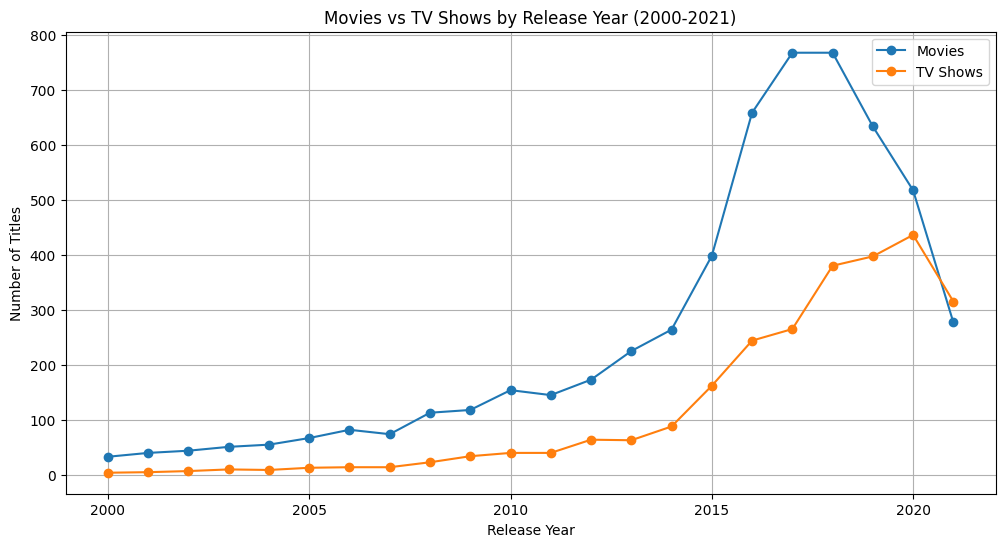

In [ ]:
recent_years = release_type_pivot.loc[2000:]
plt.figure(figsize=(12,6))
plt.plot(recent_years.index, recent_years["Movie"], marker = "o", label = "Movies")
plt.plot(recent_years.index, recent_years["TV Show"], marker = "o", label = "TV Shows")

plt.title("Movies vs TV Shows by Release Year (2000-2021)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.show()

# **Interpretation**

The analysis shows that Movies outnumbered TV Shows for most of the release years in the dataset. The number of Movies increased significantly between 2015 and 2018, reaching 767 titles in both 2017 and 2018. However, the number of TV Shows increased more strongly in the later years. The difference between Movies and TV Shows became much smaller in 2019 and 2020, and in 2021 TV Shows (315) exceeded Movies (277). This suggests that TV Shows became an increasingly important part of the Netflix content represented in the dataset in the later release years.

# **Research Question 2**

In [ ]:
country_df = df.copy()
country_df["country"] = country_df["country"].str.split(", ")
country_df = country_df.explode("country")
print(country_df[["title", "country", "type"]].head(15))

                              title         country     type
0              Dick Johnson Is Dead   United States    Movie
1                     Blood & Water    South Africa  TV Show
2                         Ganglands         Unknown  TV Show
3             Jailbirds New Orleans         Unknown  TV Show
4                      Kota Factory           India  TV Show
5                     Midnight Mass         Unknown  TV Show
6  My Little Pony: A New Generation         Unknown    Movie
7                           Sankofa   United States    Movie
7                           Sankofa           Ghana    Movie
7                           Sankofa    Burkina Faso    Movie
7                           Sankofa  United Kingdom    Movie
7                           Sankofa         Germany    Movie
7                           Sankofa        Ethiopia    Movie
8     The Great British Baking Show  United Kingdom  TV Show
9                      The Starling   United States    Movie


In [ ]:
known_country_counts = (country_df[country_df["country"] != "Unknown"]["country"].value_counts())

top_countries = known_country_counts.head(10)

print("Top Countries: ")
print(top_countries)

Top Countries: 
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


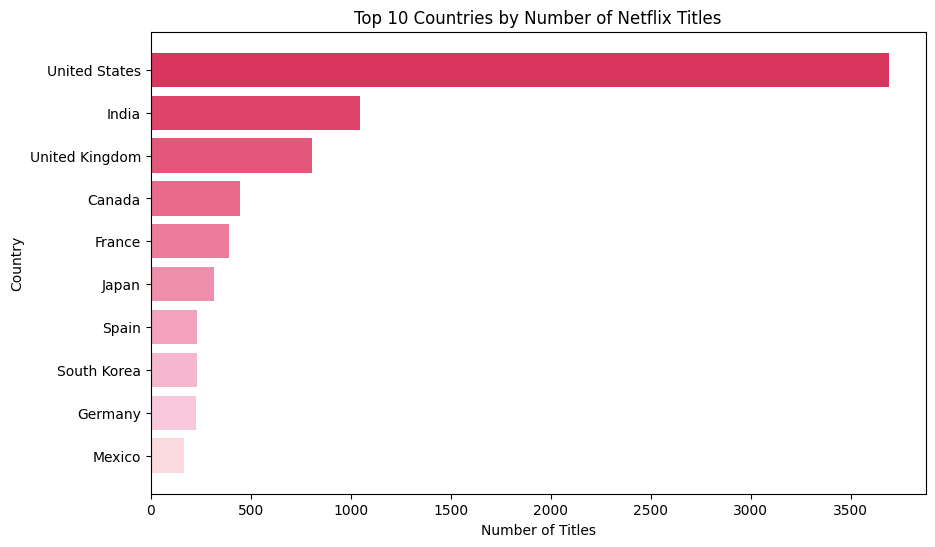

In [ ]:
plt.figure(figsize=(10, 6))
colors = [
    "#FADADD","#F8C8DC","#F5B7CD","#F2A2BC","#EF8FAB","#EC7C9A","#E96A8A","#E5577A","#E0446B","#D9365F"]

plt.barh(top_countries.sort_values().index, top_countries.sort_values().values, color = colors)

plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.show()

In [ ]:
country_type_counts = (country_df.groupby(["country", "type"]).size().unstack(fill_value=0))

print(country_type_counts.head(15))

type         Movie  TV Show
country                    
                 1        1
Afghanistan      1        0
Albania          1        0
Algeria          3        0
Angola           1        0
Argentina       71       20
Armenia          1        0
Australia       94       66
Austria         11        1
Azerbaijan       0        1
Bahamas          1        0
Bangladesh       4        0
Belarus          0        1
Belgium         78       12
Bermuda          1        0


In [ ]:
sorted_country_type = (country_type_counts.reset_index().sort_values(["Movie", "TV Show"],ascending=[False, False]))

print(sorted_country_type.head(15))

type         country  Movie  TV Show
119    United States   2751      938
47             India    962       84
117   United Kingdom    532      272
121          Unknown    440      391
22            Canada    319      126
38            France    303       90
40           Germany    182       44
105            Spain    171       61
55             Japan    119      199
25             China    114       48
69            Mexico    111       58
35             Egypt    102       15
44         Hong Kong    100        5
7          Australia     94       66
79           Nigeria     94        9


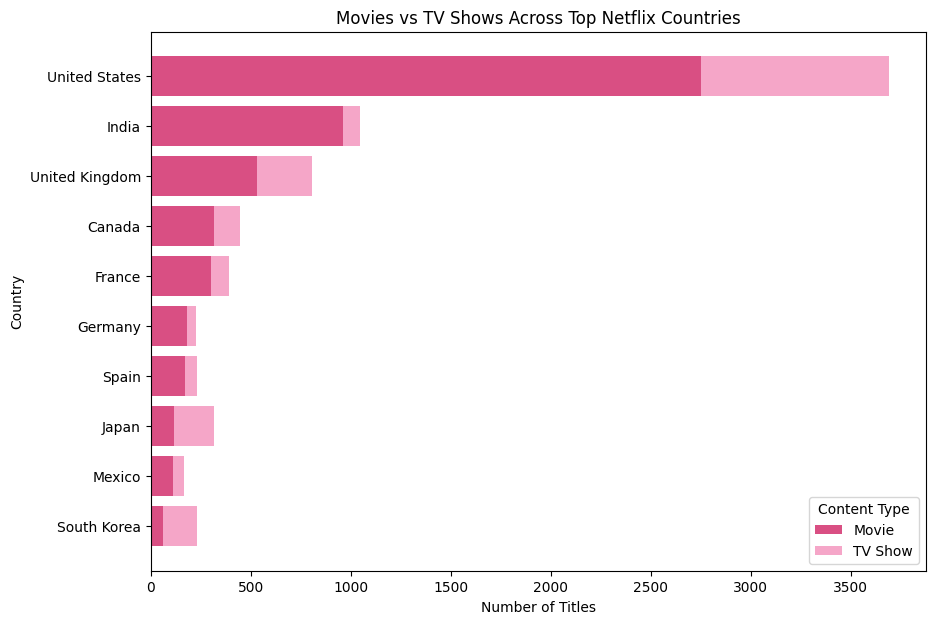

In [ ]:
top_country_type = country_type_counts.loc[country_type_counts.index.intersection(top_countries.index)]
top_country_type = top_country_type.drop(index="Unknown",errors="ignore")
sorted_data = top_country_type.sort_values("Movie")

plt.figure(figsize=(10, 7))
plt.barh(sorted_data.index,sorted_data["Movie"],color="#D94F83",label="Movie")

plt.barh(sorted_data.index,sorted_data["TV Show"],left=sorted_data["Movie"],color="#F5A6C8",label="TV Show")

plt.title("Movies vs TV Shows Across Top Netflix Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.legend(title="Content Type")

plt.show()

# **Interpretation**

The country analysis shows that the United States has the highest number of Netflix titles, with 3,689 title-country associations. India comes second with 1,046, followed by the United Kingdom with 804.The number of Movies and TV Shows also varies from country to country. The United States and India have many more Movies than TV Shows, while countries like Japan and South Korea have more TV Shows than Movies. For example, the United States has 2,751 Movies and 938 TV Shows, while South Korea has only 61 Movies but 170 TV Shows.Overall, this shows that the type of content available on Netflix is different across countries. It is also important to note that 831 titles have missing or unknown country information, so the results may not represent the complete picture.


# **Research Question 3**

In [ ]:
print(df["rating"].value_counts(dropna=False))

rating
TV-MA       3211
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


In [ ]:
rating_type_counts = df.groupby(["rating", "type"]).size().unstack(fill_value=0)
print(rating_type_counts)

print("\nUnique Ratings: ")
print(sorted(df["rating"].unique()))

type      Movie  TV Show
rating                  
66 min        1        0
74 min        1        0
84 min        1        0
G            41        0
NC-17         3        0
NR           75        5
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      733
TV-G        126       94
TV-MA      2064     1147
TV-PG       540      323
TV-Y        131      176
TV-Y7       139      195
TV-Y7-FV      5        1
UR            3        0

Unique Ratings: 
['66 min', '74 min', '84 min', 'G', 'NC-17', 'NR', 'PG', 'PG-13', 'R', 'TV-14', 'TV-G', 'TV-MA', 'TV-PG', 'TV-Y', 'TV-Y7', 'TV-Y7-FV', 'UR']


In [ ]:
unusual_ratings = ["66 min", "74 min", "84 min"]
unusual_rating_rows = df[df["rating"].isin(unusual_ratings)]
print(unusual_rating_rows[["title", "type", "duration","rating"]])
print("Unusual rating count: ",df["rating"].isin(unusual_ratings).sum())

                                     title   type duration  rating
5541                       Louis C.K. 2017  Movie  Unknown  74 min
5794                 Louis C.K.: Hilarious  Movie  Unknown  84 min
5813  Louis C.K.: Live at the Comedy Store  Movie  Unknown  66 min
Unusual rating count:  3


In [ ]:
valid_ratings = [
    "G","NC-17","NR","PG","PG-13","R","TV-14","TV-G","TV-MA","TV-PG","TV-Y","TV-Y7","TV-Y7-FV","UR"
    ]

df["Clean_rating"] = df["rating"].where(df["rating"].isin(valid_ratings), np.nan)
print(df["Clean_rating"].value_counts(dropna=False))

Clean_rating
TV-MA       3211
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
NaN            3
UR             3
Name: count, dtype: int64


In [ ]:
rating_percentage = pd.crosstab(
    df["Clean_rating"],
    df["type"],
    normalize="columns"
) * 100

print(rating_percentage.round(2))

type          Movie  TV Show
Clean_rating                
G              0.67     0.00
NC-17          0.05     0.00
NR             1.22     0.19
PG             4.68     0.00
PG-13          8.00     0.00
R             13.01     0.07
TV-14         23.29    27.39
TV-G           2.06     3.51
TV-MA         33.68    42.86
TV-PG          8.81    12.07
TV-Y           2.14     6.58
TV-Y7          2.27     7.29
TV-Y7-FV       0.08     0.04
UR             0.05     0.00


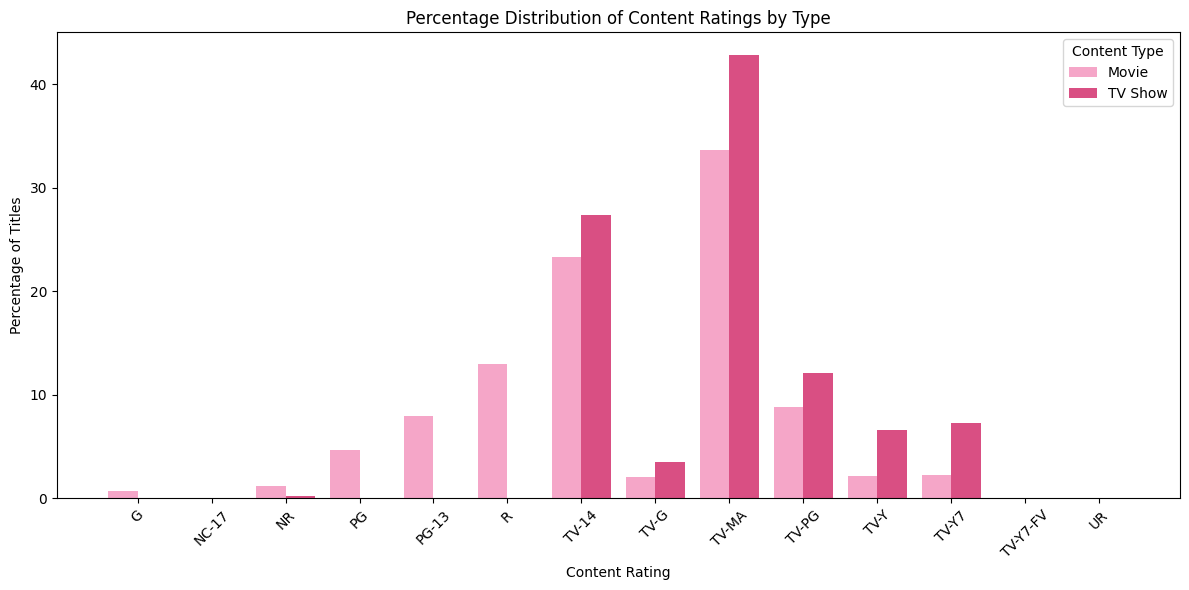

In [ ]:
plt.figure(figsize=(12, 6))

x = np.arange(len(rating_percentage.index))
width = 0.4

plt.bar(x - width/2, rating_percentage["Movie"],width, color="#F5A6C8", label="Movie")

plt.bar(x + width/2,rating_percentage["TV Show"],width,color="#D94F83",label="TV Show")

plt.title("Percentage Distribution of Content Ratings by Type")
plt.xlabel("Content Rating")
plt.ylabel("Percentage of Titles")
plt.xticks(x, rating_percentage.index, rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()

plt.show()

# **Interpretation**

TV-MA is the most common rating for both Movies (33.66%) and TV Shows (42.82%), followed by TV-14. Movies also have more R and PG-13 ratings, while TV Shows have more TV-PG, TV-Y7, and TV-Y ratings.

Some missing ratings were filled with the most common rating. Three incorrect values ("66 min", "74 min", and "84 min") were also found in the rating column.These three values were treated as invalid rating entries and converted to NaN in the Clean_rating column. They were therefore excluded from the rating comparison but not removed from the original dataset.

Overall, the rating percentages show differences between Movies and TV Shows, but the results should be interpreted carefully because some rating categories overlap.

### **Distribution Analysis**

In [ ]:
movie_duration_df = df[(df["type"] == "Movie") &(df["Movie Duration (min)"].notna())].copy()
print(movie_duration_df[["title", "Movie Duration (min)"]].head())

                               title  Movie Duration (min)
0               Dick Johnson Is Dead                  90.0
6   My Little Pony: A New Generation                  91.0
7                            Sankofa                 125.0
9                       The Starling                 104.0
12                      Je Suis Karl                 127.0


In [ ]:
duration_stats = movie_duration_df["Movie Duration (min)"].describe()
print(duration_stats)

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: Movie Duration (min), dtype: float64


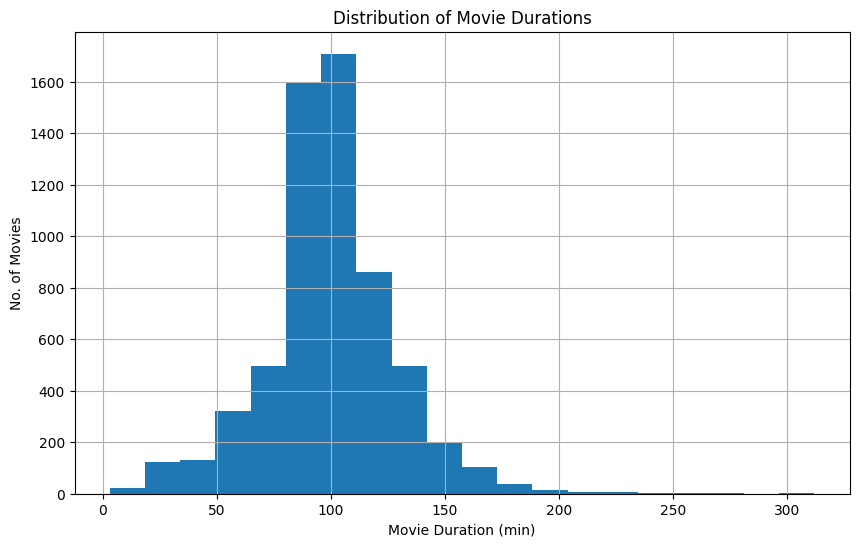

In [ ]:
plt.figure(figsize=(10,6))
plt.hist(movie_duration_df["Movie Duration (min)"], bins = 20)

plt.title("Distribution of Movie Durations")
plt.xlabel("Movie Duration (min)")
plt.ylabel("No. of Movies")
plt.grid(True)
plt.show()

### **Identifying Outliers**

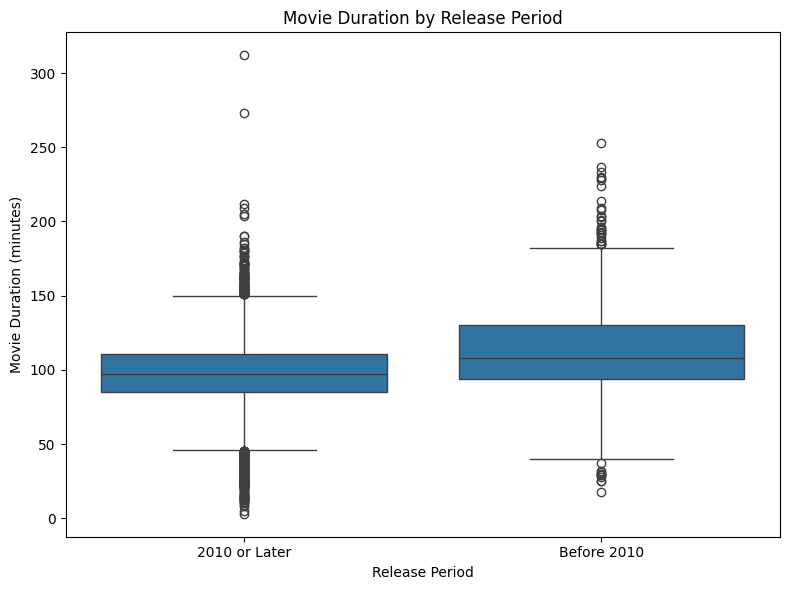

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(data=movie_duration_df,x="Release Period",y="Movie Duration (min)")

plt.title("Movie Duration by Release Period")
plt.xlabel("Release Period")
plt.ylabel("Movie Duration (minutes)")

plt.tight_layout()
plt.show()

In [ ]:
Q1 = movie_duration_df["Movie Duration (min)"].quantile(0.25)
Q3 = movie_duration_df["Movie Duration (min)"].quantile(0.75)
IQR = Q3 - Q1

print("Q1: ", Q1)
print("Q3: ", Q3)
print("IQR: ", IQR)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

Q1:  87.0
Q3:  114.0
IQR:  27.0
Lower Bound:  46.5
Upper Bound:  154.5


In [ ]:
outliers = movie_duration_df[
    (movie_duration_df["Movie Duration (min)"] < lower_bound) |
    (movie_duration_df["Movie Duration (min)"] > upper_bound)
]

print(outliers[["title", "Movie Duration (min)"]].sort_values("Movie Duration (min)"))
print("Number of Outliers: ", len(outliers))

                                                 title  Movie Duration (min)
3777                                            Silent                   3.0
2713                                       Sol Levante                   5.0
1484                                  Cops and Robbers                   8.0
1557                                            Canvas                   9.0
3535  American Factory: A Conversation with the Obamas                  10.0
...                                                ...                   ...
2484                                Lock Your Girls In                 233.0
2487                                    No Longer kids                 237.0
2491                            The School of Mischief                 253.0
717                        Headspace: Unwind Your Mind                 273.0
4253                        Black Mirror: Bandersnatch                 312.0

[450 rows x 2 columns]
Number of Outliers:  450


In [ ]:
outlier_percentage = (len(outliers) / len(movie_duration_df)) * 100
print(f"Outlier percentage: {outlier_percentage:.2f}%")

Outlier percentage: 7.34%


In [ ]:
duration_catrgory_counts = movie_duration_df["Duration Category"].value_counts()
print(duration_catrgory_counts)

Duration Category
Medium    3092
Short     1838
Long      1198
Name: count, dtype: int64


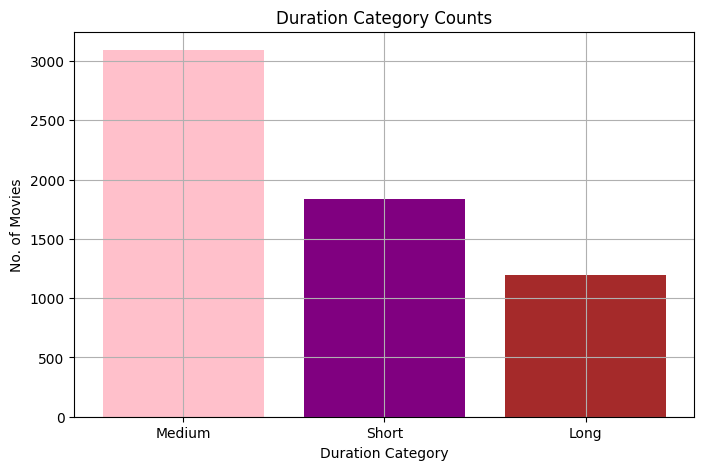

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(duration_catrgory_counts.index, duration_catrgory_counts.values, color = ["pink", "purple", "brown"])

plt.title("Duration Category Counts")
plt.xlabel("Duration Category")
plt.ylabel("No. of Movies")
plt.xticks(rotation=0)
plt.grid(True)
plt.show()

**Interpretation (Outliers)**

Most Netflix movies are between 87 and 114 minutes long. The analysis found 450 movies with unusually short or long durations. Out of these, 249 were shorter than 46.5 minutes, while 201 were longer than 154.5 minutes.

The shortest movie is Silent, at just 3 minutes, while the longest is Black Mirror: Bandersnatch, at 312 minutes. Most movies fall into the medium-length category (3,092 titles), followed by short movies (1,838) and long movies (1,198).

These unusual durations were kept in the dataset because they may represent real movies rather than errors.

### **Correlation Analysis**

In [ ]:
correlation_matrix = df[["release_year", "duration_value", "Movie Duration (min)"]].corr()
print(correlation_matrix)

                      release_year  duration_value  Movie Duration (min)
release_year              1.000000       -0.249182             -0.206285
duration_value           -0.249182        1.000000              1.000000
Movie Duration (min)     -0.206285        1.000000              1.000000


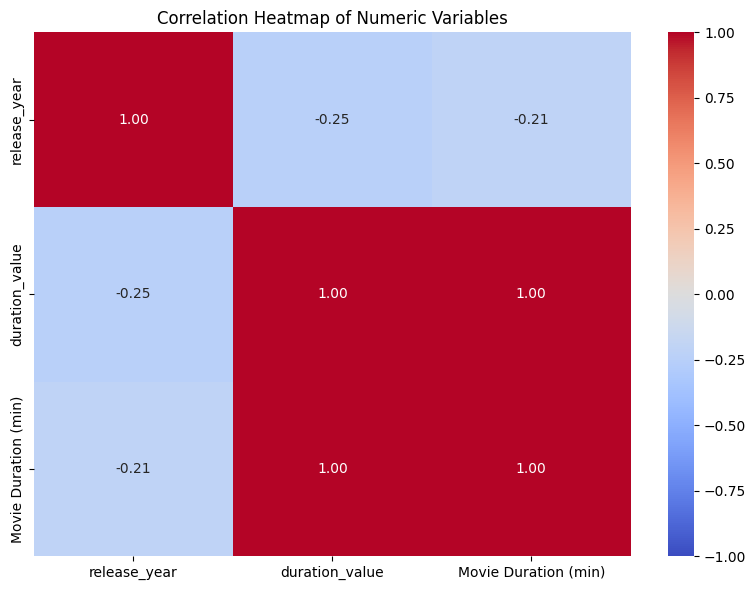

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

### **Merge and Comprehension**

In [ ]:
country_summary = (country_df.groupby("country").agg(total_titles=("title", "count"),unique_titles=("title", "nunique")).reset_index())
print(country_summary.head())

       country  total_titles  unique_titles
0                          2              2
1  Afghanistan             1              1
2      Albania             1              1
3      Algeria             3              3
4       Angola             1              1


In [ ]:
country_type_table = country_type_counts.reset_index()

print(country_type_table.head())

type      country  Movie  TV Show
0                      1        1
1     Afghanistan      1        0
2         Albania      1        0
3         Algeria      3        0
4          Angola      1        0


In [ ]:
country_merged = pd.merge(country_type_table,country_summary,on="country",how="left")

print(country_merged.head(15))

        country  Movie  TV Show  total_titles  unique_titles
0                    1        1             2              2
1   Afghanistan      1        0             1              1
2       Albania      1        0             1              1
3       Algeria      3        0             3              3
4        Angola      1        0             1              1
5     Argentina     71       20            91             91
6       Armenia      1        0             1              1
7     Australia     94       66           160            160
8       Austria     11        1            12             12
9    Azerbaijan      0        1             1              1
10      Bahamas      1        0             1              1
11   Bangladesh      4        0             4              4
12      Belarus      0        1             1              1
13      Belgium     78       12            90             90
14      Bermuda      1        0             1              1


In [ ]:
important_columns = [
    "title",
    "country",
    "rating",
    "duration",
    "release_year"
]

missing_summary = {
    column: df[column].isna().sum()
    for column in important_columns
}

print(missing_summary)

{'title': np.int64(0), 'country': np.int64(0), 'rating': np.int64(0), 'duration': np.int64(0), 'release_year': np.int64(0)}


In [ ]:
print(df.columns.tolist())
print(df["type"].value_counts())

['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'duration_value', 'Movie Duration (min)', 'Release Period', 'Duration Category', 'Clean_rating']
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


# **Final Conclusion**

The Netflix dataset shows several interesting patterns in its content. The number of TV Shows increased over the later years, while Movies remained the larger category for most of the period.

The United States has the highest number of titles, followed by India and the United Kingdom. The balance between Movies and TV Shows also differs by country, with some countries having more Movies and others, such as Japan and South Korea, having more TV Shows.

TV-MA and TV-14 are the most common ratings, especially for TV Shows. Three incorrect rating values (66 min, 74 min, and 84 min) were found and removed because they were actually movie durations. Missing ratings were filled using the most common rating.

For movie duration, most Movies are between 87 and 114 minutes. A total of 450 unusual durations were found, but they were kept because they could represent real short or long content rather than errors.

Overall, the analysis shows that Netflix has a wide variety of content in terms of type, country, ratings, and movie duration. Data cleaning, analysis, and visualizations helped provide a clearer understanding of the dataset.


# **APPLYING MACHINE LEARNING MODELS**

In [ ]:
X = df[["release_year", "country", "Clean_rating", "listed_in"]].copy()
y = df['type']

print("Features Shape : ", X.shape)
print("Target Shape : ", y.shape)

print("\nTarget Distribution : ", y.value_counts())

Features Shape :  (8807, 4)
Target Shape :  (8807,)

Target Distribution :  type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (7045, 4)
Testing features: (1762, 4)

Training target distribution:
type
Movie      4904
TV Show    2141
Name: count, dtype: int64

Testing target distribution:
type
Movie      1227
TV Show     535
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [ ]:
numeric_features = ["release_year"] #numeric

categorical_features = ["country", "Clean_rating", "listed_in"] # Categorical

# Preprocess numeric data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

# **1. Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=10, min_samples_leaf=10,random_state=42))
])

In [ ]:
dt.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['country', 'Clean_rating',
                                                   'listed_in'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=10, min_samples_leaf=10,
                                        random_state=42))])

In [ ]:
y_pred_dt = dt.predict(X_test)

Accuracy:  77.07 %

Classification Report
              precision    recall  f1-score   support

       Movie       0.89      0.77      0.82      1227
     TV Show       0.59      0.78      0.67       535

    accuracy                           0.77      1762
   macro avg       0.74      0.77      0.75      1762
weighted avg       0.80      0.77      0.78      1762



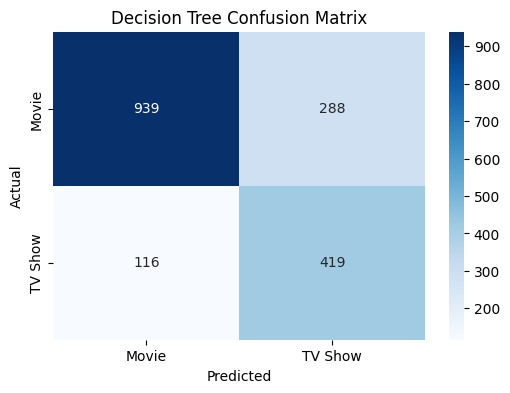

In [ ]:
print("Accuracy: ", round(accuracy_score(y_test,y_pred_dt)*100,2), "%")
print("\nClassification Report")
print(classification_report(y_test, y_pred_dt))

conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix_dt, annot=True, fmt="d", cmap="Blues", xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Checking the accuracy using Grid Search CV

In [ ]:
param_grid = {
    "classifier__max_depth" : [3, 5, 7, 10, None],
    "classifier__min_samples_leaf" : [1, 2, 5, 10],
    "classifier__min_samples_split" : [2, 10, 20]
     }

grid_search = GridSearchCV(dt, param_grid, cv=5, scoring="f1_macro", n_jobs=-1)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

print("Best cross-validation macro F1:", round(grid_search.best_score_, 3))

best_dt_model = grid_search.best_estimator_
y_pred_best = best_dt_model.predict(X_test)

print("Test Accuracy: ", round(accuracy_score(y_test, y_pred_best) *100, 2), "%")
print("\nClassification Report")
print(classification_report(y_test, y_pred_best))

Best Hyperparameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
Best cross-validation macro F1: 0.961
Test Accuracy:  97.39 %

Classification Report
              precision    recall  f1-score   support

       Movie       0.98      0.98      0.98      1227
     TV Show       0.96      0.96      0.96       535

    accuracy                           0.97      1762
   macro avg       0.97      0.97      0.97      1762
weighted avg       0.97      0.97      0.97      1762



# **Random Forest Classifier**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100,max_depth=10,class_weight="balanced",random_state=42, n_jobs=-1))
])

In [ ]:
rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['country', 'Clean_rating',
                                                   'listed_in'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        n_jobs=-1, random_state=42))])

In [ ]:
y_pred_rf = rf.predict(X_test)

Accuracy:  89.39 %

Classification Report
              precision    recall  f1-score   support

       Movie       0.97      0.87      0.92      1227
     TV Show       0.76      0.94      0.84       535

    accuracy                           0.89      1762
   macro avg       0.87      0.91      0.88      1762
weighted avg       0.91      0.89      0.90      1762



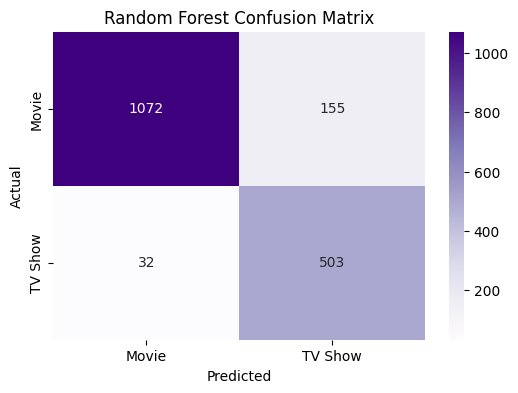

In [ ]:
print("Accuracy: ", round(accuracy_score(y_test,y_pred_rf)*100,2), "%")
print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_rf, annot=True, fmt="d", cmap="Purples", xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **KNN Classifier**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])

In [ ]:
knn.fit(X_train ,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['country', 'Clean_rating',
                                                   'listed_in'])])),
                ('classifier', KNeighborsClassifier(weights='distance'))])

In [ ]:
y_pred_knn = knn.predict(X_test)

Accuracy:  95.69 %

Classification Report
              precision    recall  f1-score   support

       Movie       0.96      0.98      0.97      1227
     TV Show       0.96      0.90      0.93       535

    accuracy                           0.96      1762
   macro avg       0.96      0.94      0.95      1762
weighted avg       0.96      0.96      0.96      1762



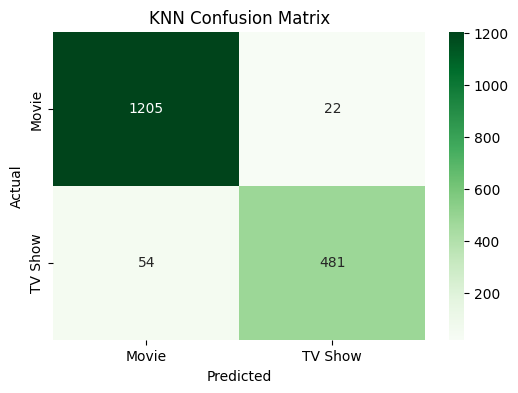

In [ ]:
print("Accuracy: ", round(accuracy_score(y_test,y_pred_knn)*100,2), "%")
print("\nClassification Report")
print(classification_report(y_test, y_pred_knn))

conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Greens", xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **Neural Network**

In [ ]:
from keras.models import Sequential
from keras.layers import Dense
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = X_train_processed.toarray()
X_test_processed = X_test_processed.toarray()

In [ ]:
y_train_nn = (y_train == "TV Show").astype(int)
y_test_nn = (y_test == "TV Show").astype(int)

In [ ]:
model = Sequential()
model.add(Dense(24, input_dim=X_train_processed.shape[1], activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 24)             │        27,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 8)              │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,713 (108.25 KB)

 Trainable params: 27,713 (108.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [ ]:
history = model.fit(X_train_processed, y_train_nn, epochs=10, batch_size=32,validation_split=0.2)

Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7383 - loss: 0.5246 - val_accuracy: 0.9418 - val_loss: 0.2711
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9800 - loss: 0.1202 - val_accuracy: 0.9865 - val_loss: 0.0563
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9968 - loss: 0.0307 - val_accuracy: 0.9908 - val_loss: 0.0287
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9995 - loss: 0.0128 - val_accuracy: 0.9957 - val_loss: 0.0195
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 0.0062 - val_accuracy: 0.9950 - val_loss: 0.0154
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 0.9950 - val_loss: 0.0133
Epoch 7/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.9950 - val_loss: 0.0122
Epoch 8/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 0.

In [ ]:
y_pred_prob = model.predict(X_test_processed)
y_pred_nn = (y_pred_prob.ravel() >= 0.5).astype(int)

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Accuracy:  99.55 %

Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1227
     TV Show       0.99      0.99      0.99       535

    accuracy                           1.00      1762
   macro avg       1.00      0.99      0.99      1762
weighted avg       1.00      1.00      1.00      1762



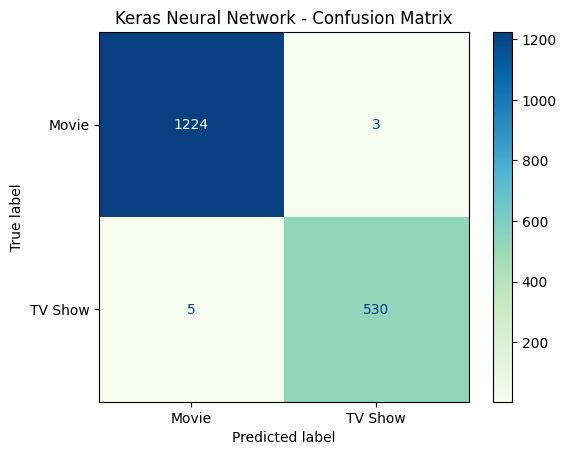

In [ ]:
print("Accuracy: ", round(accuracy_score(y_test_nn, y_pred_nn) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred_nn, labels=[0, 1], target_names=["Movie", "TV Show"]))

ConfusionMatrixDisplay.from_predictions(y_test_nn,y_pred_nn,display_labels=["Movie", "TV Show"],cmap="GnBu")
plt.title("Keras Neural Network - Confusion Matrix")
plt.show()

In [ ]:
#performance on training data
train_loss, train_accuracy = model.evaluate(X_train_processed, y_train_nn, verbose=0)

#performance on test data
test_loss, test_accuracy = model.evaluate(X_test_processed, y_test_nn, verbose=0)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print("Training Loss:", round(train_loss, 4))
print("Testing Loss:", round(test_loss, 4))

Training Accuracy: 99.9 %
Testing Accuracy: 99.55 %
Training Loss: 0.0026
Testing Loss: 0.0105


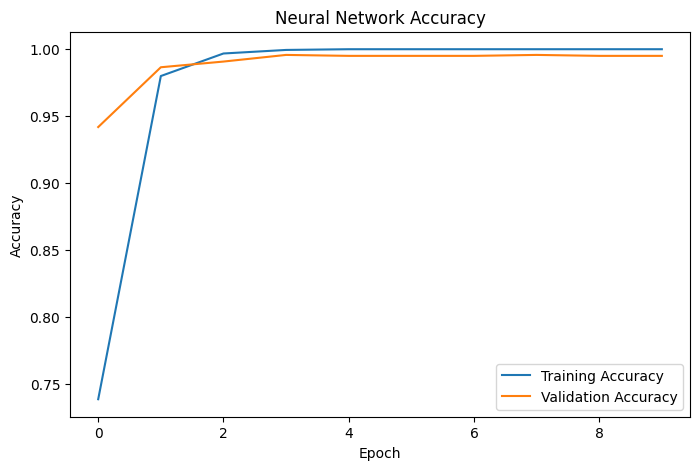

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

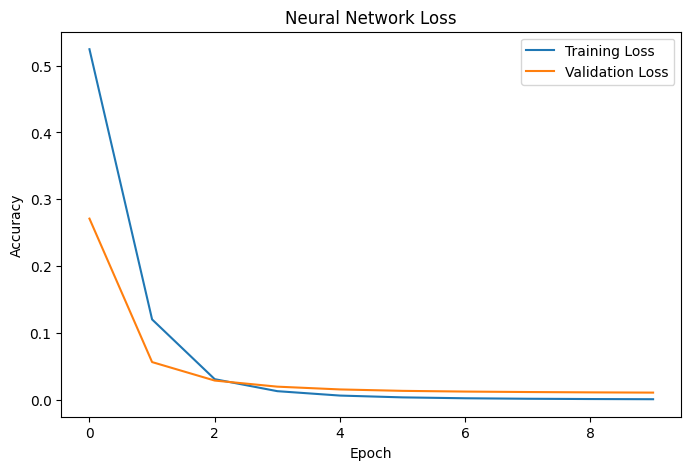

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# **Comparison**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score, classification_report, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

predictions = {
    "Decision Tree": dt.predict(X_test),
    "Random Forest": rf.predict(X_test),
    "KNN": knn.predict(X_test),
    "Neural Network": np.where(y_pred_nn == 1, "TV Show", "Movie")
}

results = {}

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(name.center(60))
    print("=" * 60)

    print(classification_report(y_test, y_pred))

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="TV Show", zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label="TV Show", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label="TV Show", zero_division=0)
    }

results_df = pd.DataFrame(results).T

print("\nMODEL COMPARISON")
print((results_df * 100).round(2))


                       Decision Tree                        
              precision    recall  f1-score   support

       Movie       0.89      0.77      0.82      1227
     TV Show       0.59      0.78      0.67       535

    accuracy                           0.77      1762
   macro avg       0.74      0.77      0.75      1762
weighted avg       0.80      0.77      0.78      1762


                       Random Forest                        
              precision    recall  f1-score   support

       Movie       0.97      0.87      0.92      1227
     TV Show       0.76      0.94      0.84       535

    accuracy                           0.89      1762
   macro avg       0.87      0.91      0.88      1762
weighted avg       0.91      0.89      0.90      1762


                            KNN                             
              precision    recall  f1-score   support

       Movie       0.96      0.98      0.97      1227
     TV Show       0.96      0.90      0.93       5

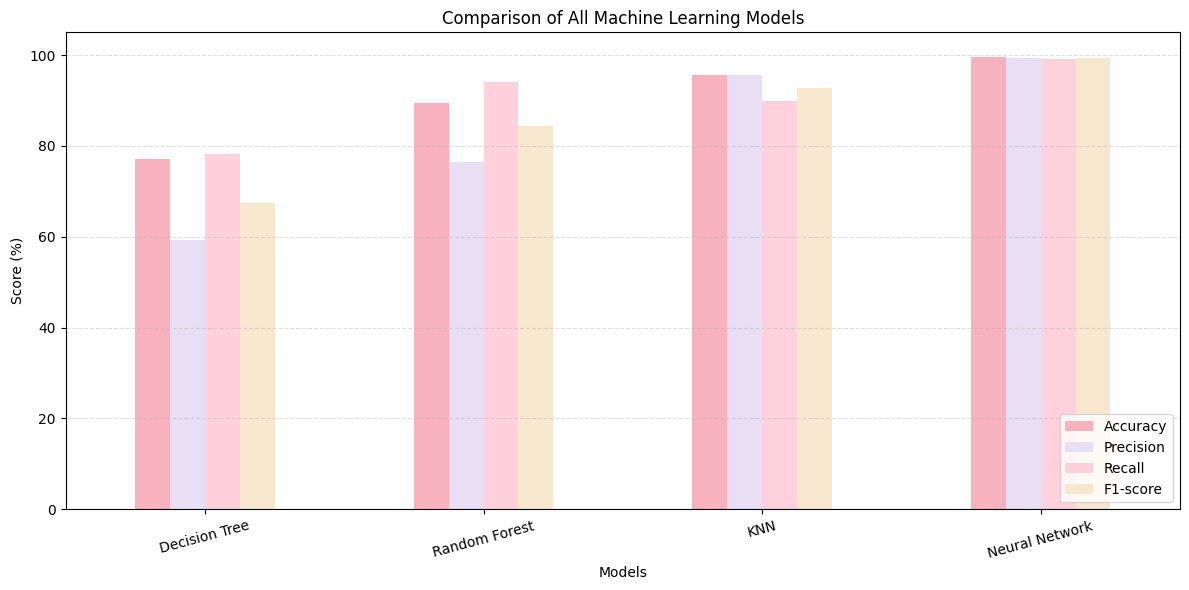

In [ ]:
results_df.mul(100).plot(kind="bar", figsize=(12, 6), color = ["#F7B2BD", "#E8DFF5", "#FFD1DC", "#F7E7CE"])

plt.title("Comparison of All Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


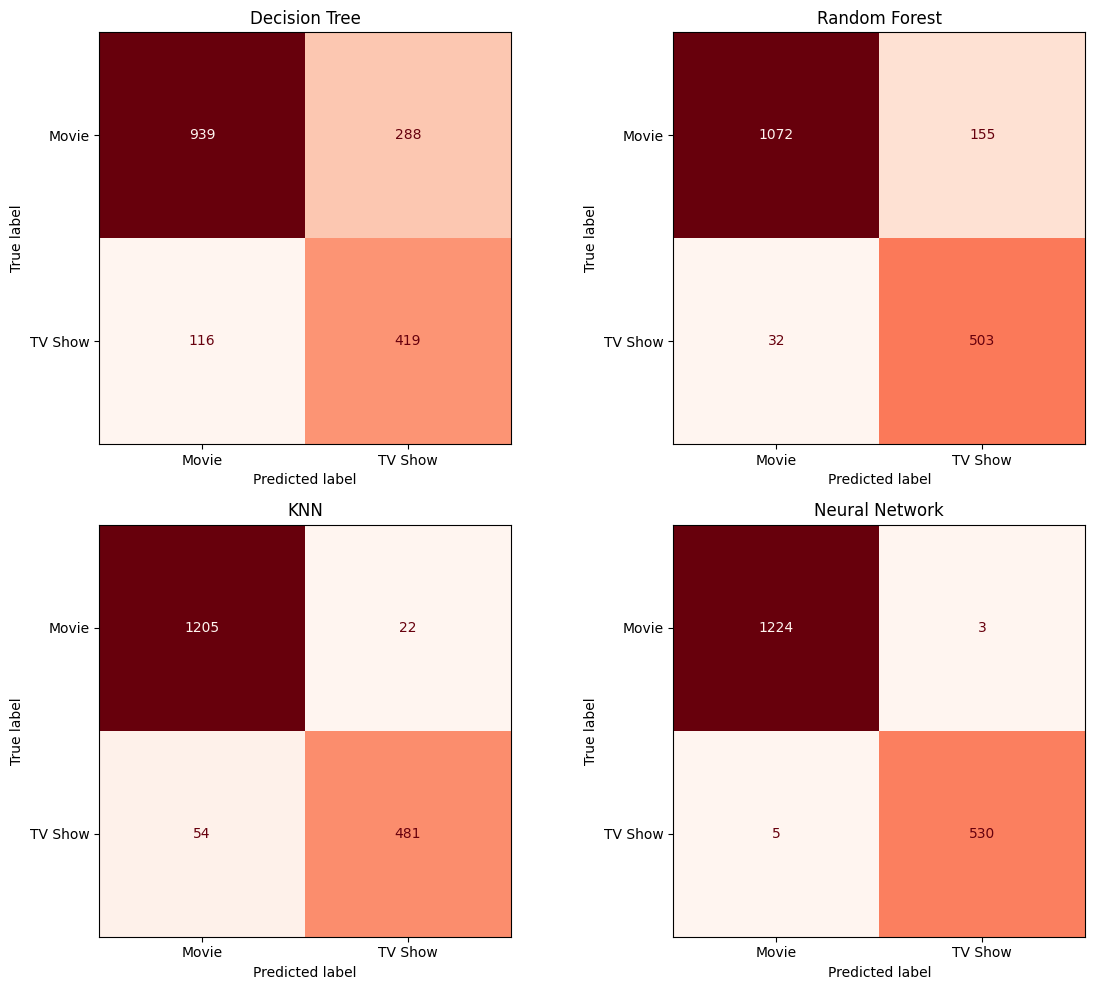

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=["Movie", "TV Show"],ax=ax,cmap="Reds",colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

trained_ml_models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn
}

for name, model_cv in trained_ml_models.items():

    scores = cross_validate(
        model_cv,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    print(f"\n{name}")
    print("Fold accuracies:",
          np.round(scores["test_accuracy"], 4))
    print("Mean accuracy:",
          round(scores["test_accuracy"].mean() * 100, 2), "%")
    print("Mean macro F1:",
          round(scores["test_f1_macro"].mean(), 4))


Decision Tree
Fold accuracies: [0.7977 0.7821 0.8105 0.7828 0.7857]
Mean accuracy: 79.18 %
Mean macro F1: 0.7535

Random Forest
Fold accuracies: [0.8992 0.8687 0.8992 0.885  0.8829]
Mean accuracy: 88.7 %
Mean macro F1: 0.8747

KNN
Fold accuracies: [0.9425 0.9397 0.9425 0.9468 0.9588]
Mean accuracy: 94.61 %
Mean macro F1: 0.9352
